# 🎯 Práctica 01 — K-Means: tu primer algoritmo no supervisado

**Objetivo:** entender cómo una máquina agrupa datos *sin que nadie le diga las respuestas*.

> 💡 **Idea clave:** en el aprendizaje supervisado (lo que hiciste con Iris y Keras) el modelo recibe `x` **y** `y`. En el **no supervisado** solo recibe `x` y debe descubrir los grupos por sí solo.

**K-Means en 3 pasos:**
1. Elige `k` centros (centroides) al azar.
2. Asigna cada punto al centroide más cercano.
3. Mueve cada centroide al promedio de sus puntos. Repite 2 y 3 hasta que ya no cambien.

Trabajaremos en bloques pequeños. **Ejecuta cada celda y lee la salida antes de seguir.**

## Bloque 1 — Herramientas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

- `numpy` → arreglos numéricos
- `matplotlib` → gráficos
- `KMeans` → el algoritmo, ya implementado en scikit-learn

## Bloque 2 — Datos de juguete (1 dimensión)

Imagina 6 clientes y cuánto gastó cada uno. ¿Hay grupos naturales?

In [2]:
gastos = np.array([1, 2, 2, 8, 9, 2])
gastos

array([1, 2, 2, 8, 9, 2])

Scikit-learn exige que `x` sea una **tabla** (filas = muestras, columnas = características).
Nuestro arreglo es una lista plana, así que lo convertimos a **6 filas × 1 columna**:

In [3]:
x = gastos.reshape(-1, 1)
print("forma antes:", gastos.shape)
print("forma después:", x.shape)
x

forma antes: (6,)
forma después: (6, 1)


array([[1],
       [2],
       [2],
       [8],
       [9],
       [2]])

> 🧠 `-1` significa *"calcula tú este tamaño"*. `reshape(-1, 1)` = "las filas que hagan falta, 1 columna".

## Bloque 3 — Crear y entrenar el modelo

In [4]:
model = KMeans(n_clusters=2, random_state=42, n_init=10)
model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 1)","[[1.7

- `n_clusters=2` → le pedimos 2 grupos (**tú** decides `k`)
- `random_state=42` → fija el azar para que todos obtengan el mismo resultado
- `n_init=10` → repite el algoritmo 10 veces con centros iniciales distintos y se queda con el mejor
- `.fit(x)` → aquí ocurre el "aprendizaje" (ojo: no pasamos `y`)

## Bloque 4 — Leer los resultados

In [5]:
print("Etiquetas :", model.labels_)
print("Centroides :", model.cluster_centers_.flatten())

Etiquetas : [0 0 0 1 1 0]
Centroides : [1.75 8.5 ]


- `labels_` → a qué grupo (0 o 1) quedó asignada **cada** muestra, en el mismo orden que `x`
- `cluster_centers_` → el "punto promedio" de cada grupo

❓ **Pregunta:** ¿los valores 1, 2, 2, 2 quedaron en el mismo grupo? ¿y el 8 y el 9? ¿Tiene sentido?

## Bloque 5 — Verlo con un gráfico

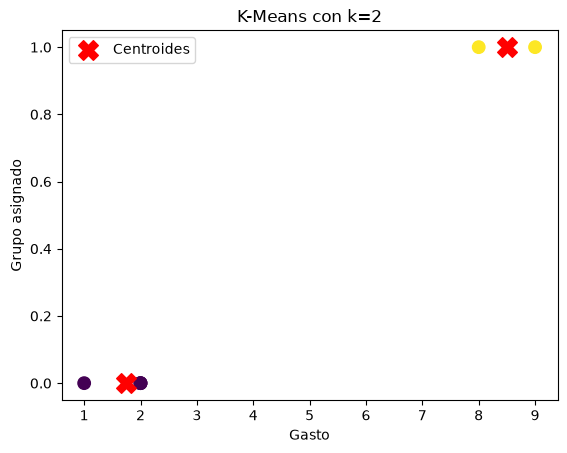

In [6]:
plt.scatter(x.flatten(), model.labels_, c=model.labels_, s=80)
plt.scatter(model.cluster_centers_.flatten(), [0, 1], marker="X", s=200, c="red", label="Centroides")
plt.xlabel("Gasto")
plt.ylabel("Grupo asignado")
plt.title("K-Means con k=2")
plt.legend()
plt.show()

## ✍️ Ejercicio A (hazlo tú)

Con estos datos: `[2, 4, 5, 20, 21, 25, 50, 40]` y **k = 3**:

1. Crea el arreglo `x` con la forma correcta.
2. Entrena un `KMeans`.
3. Imprime etiquetas y centroides.
4. Grafícalo.

*Pista: copia los bloques 3, 4 y 5 y cambia solo lo necesario.*

In [7]:
# Tu código aquí

## Bloque 6 — Ahora en 2 dimensiones

Cada cliente tiene dos características: `[compras_al_mes, monto_promedio]`.

In [8]:
clientes = np.array([[100, 50], [120, 60],
                     [400, 200], [380, 220],
                     [700, 300], [720, 320]])

model2 = KMeans(n_clusters=3, random_state=42, n_init=10)
model2.fit(clientes)

etiquetas = model2.labels_
centros = model2.cluster_centers_
print("Etiquetas:", etiquetas)
print("Centroides:\n", centros)

Etiquetas: [2 2 0 0 1 1]
Centroides:
 [[390. 210.]
 [710. 310.]
 [110.  55.]]


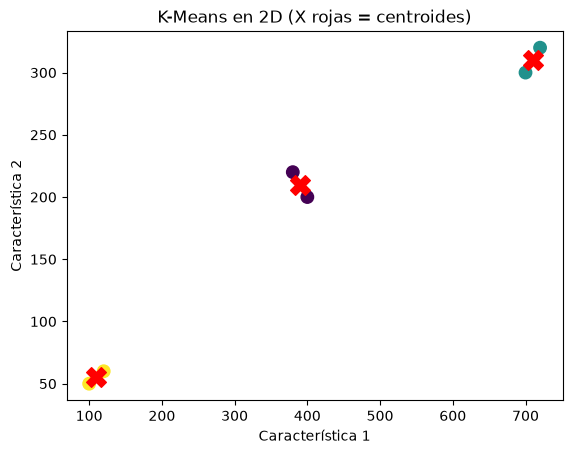

In [9]:
plt.scatter(clientes[:, 0], clientes[:, 1], c=etiquetas, s=80)
plt.scatter(centros[:, 0], centros[:, 1], marker="X", s=200, c="red")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.title("K-Means en 2D (X rojas = centroides)")
plt.show()

> 🧠 `clientes[:, 0]` = *todas las filas, columna 0*. Es el patrón que más usarás para graficar.

## ✍️ Ejercicio B (hazlo tú)

Cambia `n_clusters` a **2** y luego a **4** en el Bloque 6. ¿Qué pasa con los grupos? ¿Cuál `k` te parece más razonable y por qué?
*(Spoiler: el siguiente tema responde esto con el **método del codo**.)*

In [10]:
# Tu código aquí

## 🧾 Resumen de la clase

| Concepto | En una frase |
|---|---|
| No supervisado | Solo `x`, sin respuestas `y` |
| `KMeans(n_clusters=k)` | Tú eliges cuántos grupos buscar |
| `.fit(x)` | Entrena (calcula los centroides) |
| `.labels_` | Grupo de cada muestra |
| `.cluster_centers_` | Centro de cada grupo |
| `reshape(-1, 1)` | Convierte una lista plana en tabla de 1 columna |

**Siguiente práctica:** K-Means con datos reales (Iris) y comparar los grupos con las etiquetas verdaderas.